- would create neural network by nn module
- built-in loss function with nn
- apply activation fun ction using nn module
- use torch.optim for updation


# NN without Hidden Layer




In [ ]:
import torch
import torch.nn as nn

class Model(nn.Module):
       def __init__(self,num_features):
              super().__init__()
              self.linear = nn.Linear(num_features,1) # nn.linear(input,output)
              self.sigmoid=nn.Sigmoid()
       def forward(self,features):
              out=self.linear(features)
              out=self.sigmoid(out)
              return out


In [ ]:
#create dataset

features=torch.rand(10,5)

#create model
model=Model(features.shape[1])

# call model for forward pass
model(features)  #same as model.forward -> it trigger the forward funcn inside class Model



tensor([[0.5762],
        [0.5614],
        [0.6313],
        [0.6091],
        [0.5958],
        [0.5642],
        [0.5715],
        [0.6290],
        [0.5621],
        [0.6503]], grad_fn=<SigmoidBackward0>)

In [ ]:
model.linear.weight

Parameter containing:
tensor([[-0.2006,  0.0311,  0.3522, -0.3358,  0.3124]], requires_grad=True)

In [ ]:
model.linear.bias



Parameter containing:
tensor([0.2648], requires_grad=True)

In [ ]:
!pip install torchinfo

In [ ]:
from torchinfo import summary
summary(model,input_size=(10,5))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [10, 1]                   --
├─Linear: 1-1                            [10, 1]                   6
├─Sigmoid: 1-2                           [10, 1]                   --
Total params: 6
Trainable params: 6
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

# NN with Hidden Layer

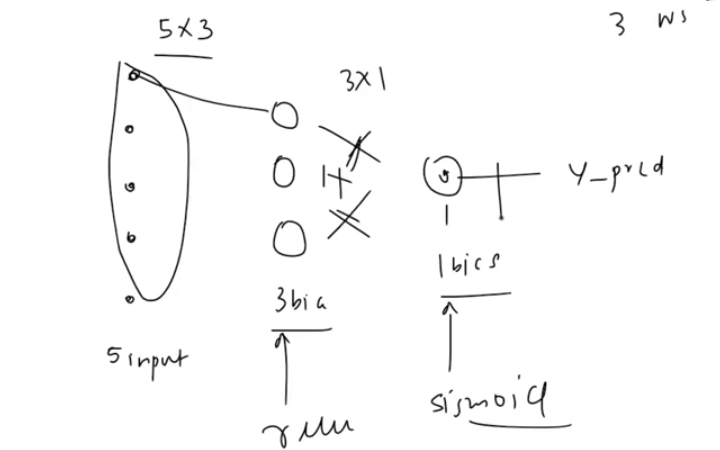

In [ ]:
import torch
import torch.nn as nn

class Model(nn.Module):
        def __init__(self,num_features):
               super().__init__()
               self.linear1 = nn.Linear(num_features,3)  #first layer(as input layer ) that gives 3 features as o/p , i/p for hidden layer
               self.relu=nn.ReLU() # hidden layer activation function
               self.linear2=nn.Linear(3,1)
               self.sigmoid=nn.Sigmoid( ) #o/p layer
        def forward(self,features):
               out=self.linear1(features)
               out=self.relu(out)
               out=self.linear2(out)
               out=self.sigmoid(out)
               return out

In [ ]:
features=torch.rand(10,5)

#create model
model=Model(features.shape[1])

In [ ]:
model(features)

tensor([[0.6231],
        [0.6098],
        [0.6211],
        [0.6364],
        [0.6104],
        [0.6481],
        [0.6036],
        [0.6487],
        [0.6354],
        [0.6522]], grad_fn=<SigmoidBackward0>)

In [ ]:
model.linear1.weight

Parameter containing:
tensor([[ 0.0167,  0.2386,  0.3043,  0.0608,  0.1981],
        [ 0.3619, -0.0232, -0.3205,  0.0205,  0.1467],
        [ 0.2047,  0.2246,  0.0800,  0.3001, -0.3884]], requires_grad=True)

In [ ]:
from torchinfo import summary
summary(model,input_size=(10,5))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [10, 1]                   --
├─Linear: 1-1                            [10, 3]                   18
├─ReLU: 1-2                              [10, 3]                   --
├─Linear: 1-3                            [10, 1]                   4
├─Sigmoid: 1-4                           [10, 1]                   --
Total params: 22
Trainable params: 22
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

### parameters() and state_dict()

In [ ]:
import torch.nn as nn

layer = nn.Linear(10, 3)
for param in layer.parameters():
  print(param)

print("State dict are: ",layer.state_dict())

Parameter containing:
tensor([[-0.2939, -0.0107,  0.0413, -0.1573, -0.2455, -0.0936, -0.2616, -0.1196,
          0.2377,  0.1208],
        [ 0.3154,  0.1015,  0.0727, -0.1342,  0.2303, -0.1559,  0.2935,  0.2647,
          0.2919, -0.1761],
        [ 0.0043, -0.2558,  0.2153, -0.1475, -0.0478, -0.1431, -0.0269, -0.0310,
         -0.0660,  0.1829]], requires_grad=True)
Parameter containing:
tensor([ 0.3018, -0.0860,  0.2733], requires_grad=True)
State dict are:  OrderedDict({'weight': tensor([[-0.2939, -0.0107,  0.0413, -0.1573, -0.2455, -0.0936, -0.2616, -0.1196,
          0.2377,  0.1208],
        [ 0.3154,  0.1015,  0.0727, -0.1342,  0.2303, -0.1559,  0.2935,  0.2647,
          0.2919, -0.1761],
        [ 0.0043, -0.2558,  0.2153, -0.1475, -0.0478, -0.1431, -0.0269, -0.0310,
         -0.0660,  0.1829]]), 'bias': tensor([ 0.3018, -0.0860,  0.2733])})


# Containers
### contains the layers

In [ ]:
class Bad(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(4, 4) for _ in range(3)]    # plain list

class Good(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(4, 4) for _ in range(3)])

for cls in (Bad, Good):
    m = cls()
    print(cls.__name__, len(list(m.parameters())), list(m.state_dict().keys())[:2])
# Bad  0  []
# Good 6  ['layers.0.weight', 'layers.0.bias']

Bad 0 []
Good 6 ['layers.0.weight', 'layers.0.bias']


## A)Sequential()


output of station 1 is the input of station 2, and so on. Its whole forward is a loop:

In [ ]:
import torch.nn as nn
model=nn.Sequential(
    nn.Linear(10,4),
    nn.ReLU(),
    nn.Linear(4,2),
    nn.ReLU(),
    nn.Linear(2,1),
    nn.Softmax()
)

In [ ]:
model

Sequential(
  (0): Linear(in_features=10, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=2, bias=True)
  (3): ReLU()
  (4): Linear(in_features=2, out_features=1, bias=True)
  (5): Softmax(dim=None)
)

Things worth knowing:

* Naming: default names are "0", "1", "2". Pass an OrderedDict for readable names (net.fc1).
* Indexing: net[0] is the first layer. net[-1] is the last layer.
* Slicing returns a new Sequential that shares the same layer objects, so the parameters are shared, not copied. net[:2] is a handy way to extract "the feature part" of a pretrained model.
* Editing: .append(), .insert(), .extend(), and del net[1] all work. Swapping a layer: net[2] = nn.Linear(32, 5) (common when replacing a classifier head).
* Limits: exactly one input and one output per station. No skip connections, no branching, no logic in between.





In [ ]:
model[0]=nn.Linear(20,10) #changing the layer parameters

In [ ]:
model

Sequential(
  (0): Linear(in_features=20, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=2, bias=True)
  (3): ReLU()
  (4): Linear(in_features=2, out_features=1, bias=True)
  (5): Softmax(dim=None)
)

In [ ]:
model.append(nn.Tanh()) #appending


Sequential(
  (0): Linear(in_features=20, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=2, bias=True)
  (3): ReLU()
  (4): Linear(in_features=2, out_features=1, bias=True)
  (5): Softmax(dim=None)
  (6): Tanh()
)

In [ ]:
import torch.nn as nn
model=nn.Sequential(
    nn.Linear(20,10),
    nn.ReLU(),
    nn.Linear(10,20),
    nn.ReLU(),
    nn.Linear(20,1),
    nn.Sigmoid()
)
print(model)


Sequential(
  (0): Linear(in_features=20, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=20, bias=True)
  (3): ReLU()
  (4): Linear(in_features=20, out_features=1, bias=True)
  (5): Sigmoid()
)


### Naming the Layers

In [ ]:
import torch.nn as nn
from collections import OrderedDict
model=nn.Sequential(OrderedDict([
    ("input layer", nn.Linear(10,20) ),
    ("ReLU1",nn.ReLU()),
    ("hidden layer",nn.Linear(20,10)),
    ("Relu2",nn.ReLU()),
    ("Output",nn.Linear(10,1)),
    ("Sigmoid",nn.Sigmoid())
]))

print(model)

Sequential(
  (input layer): Linear(in_features=10, out_features=20, bias=True)
  (ReLU1): ReLU()
  (hidden layer): Linear(in_features=20, out_features=10, bias=True)
  (Relu2): ReLU()
  (Output): Linear(in_features=10, out_features=1, bias=True)
  (Sigmoid): Sigmoid()
)


### Forward Pass

In [ ]:
x=torch.randn(1,10)
y=model(x)
y #output after forward pass

tensor([[0.4645]], grad_fn=<SigmoidBackward0>)

### Loss Calculation

In [ ]:
import torch
import torch.nn as nn

loss_fn=nn.BCELoss()
target=torch.tensor([[1.0]])
loss=loss_fn(y,target)
loss_val=loss.item()
print(loss_val)

0.7667196989059448


In [ ]:
nn.parameter

<module 'torch.nn.parameter' from '/usr/local/lib/python3.13/dist-packages/torch/nn/parameter.py'>

##One Complete training loop


In [ ]:
import torch
import torch.nn as nn
from collections import OrderedDict

model=nn.Sequential(OrderedDict([
    ("Input Layer ",nn.Linear(10,20)) , ("ReLU1", nn.ReLU()),
    ("Hidden Layer",nn.Linear(20,10)) , ("ReLU2",nn.ReLU()),
    ("Output",nn.Linear(10,1)) , ("Sigmoid",nn.Sigmoid())

]))
loss_fn=nn.BCELoss()
optimizer=torch.optim.Adam(model.parameters(), lr=1e-3)
#fake data
x=torch.randn(100,10)
y=torch.randint(0,2,(100,1)).float()
#training loop
for epoch in range(51):
     optimizer.zero_grad()  # clear old gradient
     pred=model(x)              # forward pass
     loss=loss_fn(pred,y)       # loss calculation
     loss.backward()            # backward pass
     optimizer.step()             # weights updation


     if epoch%10==0:
      print(f"Epoch : {epoch} , Loss : {loss.item() : .4f}")

Epoch : 0 , Loss :  0.7040
Epoch : 10 , Loss :  0.6963
Epoch : 20 , Loss :  0.6896
Epoch : 30 , Loss :  0.6832
Epoch : 40 , Loss :  0.6762
Epoch : 50 , Loss :  0.6682


## B) ModuleList()

In [ ]:
import torch
import torch.nn as nn

class ResidualMLP(nn.Module):
    def __init__(self, dim, depth):
        super().__init__()
        self.blocks = nn.ModuleList([nn.Linear(dim, dim) for _ in range(depth)])

    def forward(self, x):
        # 1. Print state *inside* the execution loop to see changes layer by layer
        for i, block in enumerate(self.blocks):
            x = x + torch.relu(block(x))
            print(f"-> Tensor output after layer {i}:\n   {x.detach()}\n")
        return x

a = ResidualMLP(3, 5)
inp = torch.tensor([[1.0, 2.0, 3.0]])

print("=== METHOD 1: Printing the layers directly from the ModuleList ===\n")
# You can loop over 'a.blocks' to inspect the layers directly!
for i, layer in enumerate(a.blocks):
    print(f"Layer index {i} Structural Setup: {layer}")
print("\n=== METHOD 2: Running data to see output step-by-step ===\n")
a(inp) #forward pass->> passing inp to the a


=== METHOD 1: Printing the layers directly from the ModuleList ===

Layer index 0 Structural Setup: Linear(in_features=3, out_features=3, bias=True)
Layer index 1 Structural Setup: Linear(in_features=3, out_features=3, bias=True)
Layer index 2 Structural Setup: Linear(in_features=3, out_features=3, bias=True)
Layer index 3 Structural Setup: Linear(in_features=3, out_features=3, bias=True)
Layer index 4 Structural Setup: Linear(in_features=3, out_features=3, bias=True)

=== METHOD 2: Running data to see output step-by-step ===

-> Tensor output after layer 0:
   tensor([[3.3052, 3.9722, 3.0000]])

-> Tensor output after layer 1:
   tensor([[3.3052, 3.9722, 3.0000]])

-> Tensor output after layer 2:
   tensor([[3.3052, 3.9722, 3.0000]])

-> Tensor output after layer 3:
   tensor([[4.7368, 3.9722, 6.6069]])

-> Tensor output after layer 4:
   tensor([[ 8.8230,  3.9722, 12.9927]])



tensor([[ 8.8230,  3.9722, 12.9927]], grad_fn=<AddBackward0>)

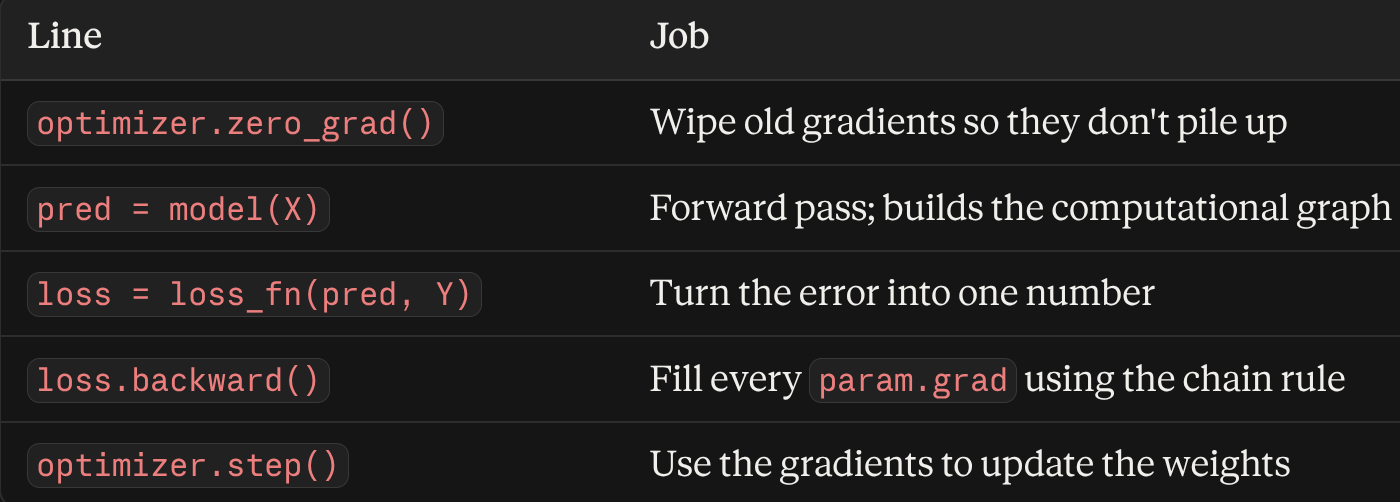

In [ ]:
!nvidia-lsm

/bin/bash: line 1: nvidia-lsm: command not found
